<a href="https://colab.research.google.com/github/RahulGupta1291/ml-assignment-2/blob/main/ML_2026AJ05022_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 — AIMLZG565 — Machine Learning

**WILP Division**
**M. Tech. in Artificial Intelligence & Machine Learning**
**I Semester 2026-27**

---

**Assignment I**

**Student Name:** RAHUL GUPTA
**BITS ID:** 2026AJ05022
**Semester:** 1st (2026-27)

---

## Multi Model Classification and App Deployment

### Problem statement
In this assignment, we have to implement the following:
- Implement multiple classification models
- Build an interactive Streamlit web application to demonstrate your models
- Deploy the app on Streamlit Community Cloud (FREE)
---

## Dataset Used
Heart Disease Prediction Dataset 2026

https://www.kaggle.com/datasets/mohankrishnathalla/heart-disease-prediction-dataset-2026


In [63]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import math

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay
)

np.random.seed(12)

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.autolayout": True, "axes.titleweight": "bold"})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading the data

In [67]:
train  = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/heart_disease_train.csv')
test   = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/heart_disease_test.csv')

for name, df in [("bike_train", train), ("bike_test", test)]:
    print(f"Dataset: {name:18s} \nShape: {str(df.shape):12s} \nColoumns: {list(df.columns)}\n\n")

Dataset: bike_train         
Shape: (1800, 26)   
Coloumns: ['age', 'sex', 'bmi', 'region', 'income_level', 'smoking_status', 'alcohol_intake', 'physical_activity', 'diet_quality', 'sleep_hours', 'stress_level', 'diabetes', 'hypertension', 'family_history', 'previous_heart_event', 'resting_bp', 'cholesterol', 'fasting_blood_sugar', 'max_heart_rate', 'resting_ecg', 'exercise_angina', 'st_depression', 'st_slope', 'avg_resting_hr', 'hrv_score', 'heart_disease']


Dataset: bike_test          
Shape: (200, 26)    
Coloumns: ['age', 'sex', 'bmi', 'region', 'income_level', 'smoking_status', 'alcohol_intake', 'physical_activity', 'diet_quality', 'sleep_hours', 'stress_level', 'diabetes', 'hypertension', 'family_history', 'previous_heart_event', 'resting_bp', 'cholesterol', 'fasting_blood_sugar', 'max_heart_rate', 'resting_ecg', 'exercise_angina', 'st_depression', 'st_slope', 'avg_resting_hr', 'hrv_score', 'heart_disease']




In [68]:
# ------ Printing first 5 rows of the datasets to view the columns and entry type ------
print("irst 5 Rows of Training Dataset:")
display(train.head())
print("\n\nFirst 5 Rows of Test Dataset:")
display(test.head())

irst 5 Rows of Training Dataset:


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,57,Male,27.1,Northeast,Middle,Never,Moderate,Light,7,5.7,...,204,0,195,Normal,0,0.9,Downsloping,61.8,19.9,0
1,40,Female,29.0,Northeast,Low,Never,Non-drinker,Sedentary,1,8.0,...,173,0,165,ST-T Abnormality,0,0.5,Downsloping,53.2,48.3,0
2,63,Female,40.1,Southeast,High,Never,Moderate,Sedentary,6,5.5,...,209,0,173,Normal,0,2.3,Downsloping,82.3,5.0,1
3,66,Female,35.5,West,Middle,Never,Heavy,Sedentary,10,7.4,...,187,0,144,Normal,0,1.3,Downsloping,71.1,38.3,1
4,29,Female,19.8,Northeast,High,Current,Non-drinker,Sedentary,8,8.3,...,247,0,170,ST-T Abnormality,0,0.4,Downsloping,74.1,49.4,0




First 5 Rows of Test Dataset:


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,55,Male,23.0,Midwest,Low,Never,Non-drinker,Sedentary,5,8.3,...,248,0,165,Left Ventricular Hypertrophy,0,0.4,Upsloping,81.9,56.7,0
1,45,Female,31.5,Southeast,Low,Never,Moderate,Light,6,7.2,...,214,1,160,Normal,0,1.0,Upsloping,63.2,76.0,0
2,57,Male,30.8,Southeast,High,Former,Non-drinker,Sedentary,2,6.1,...,183,0,186,ST-T Abnormality,1,1.7,Flat,67.1,52.8,0
3,48,Male,34.0,Northeast,High,Never,Moderate,Active,8,8.9,...,181,1,192,ST-T Abnormality,1,2.7,Flat,57.4,37.8,0
4,29,Male,28.4,Southeast,Middle,Never,Moderate,Light,4,6.8,...,262,1,202,ST-T Abnormality,0,0.2,Downsloping,60.2,50.3,0


## Examine dataset size, missing values, and feature types

In [69]:
print(f"Training set : {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Test set     : {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"Total        : {train.shape[0] + test.shape[0]:,} rows")
print("\n\nInformation about the Current Training dataset:")
train.info()

# ---- Information about missing values in the datasets ----
print("\n\nMissing values in train:", int(train.isna().sum().sum()))
print("Missing values in test :", int(test.isna().sum().sum()))
print("Fully duplicated rows in train:", int(train.duplicated().sum()))

# ---- Numeric analysis of the Target variable ----
y_full = train["heart_disease"].values
print("\n\nNumeric analysis of the Target variable:")
display(train["heart_disease"].describe().to_frame().T)
print(f"skewness of heart_disease        : {train['heart_disease'].skew():.3f}")

# ---- Information about the continous variables in the Train dataset ----
print("\n\nInformation about the continous variables in the Current Training dataset:")
display(train[["age", "bmi", "sleep_hours", "diet_quality", "stress_level", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"]].describe().T)

# ---- Checking balance of the categorical variables in the dataset ----
print("\n\nChecking balance of the categorical variables in the dataset:")
for c in ["sex", "region", "income_level", "smoking_status", "alcohol_intake", "physical_activity", "diabetes", "hypertension", "family_history", "previous_heart_event", "fasting_blood_sugar", "resting_ecg", "exercise_angina", "st_slope"]:
    vc = train[c].value_counts().sort_index()
    print(f"{c:12s}", " | ".join(f"{k}:{v}" for k, v in vc.items()))

Training set : 1,800 rows x 26 columns
Test set     : 200 rows x 26 columns
Total        : 2,000 rows


Information about the Current Training dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1800 non-null   int64  
 1   sex                   1800 non-null   object 
 2   bmi                   1800 non-null   float64
 3   region                1800 non-null   object 
 4   income_level          1800 non-null   object 
 5   smoking_status        1800 non-null   object 
 6   alcohol_intake        1800 non-null   object 
 7   physical_activity     1800 non-null   object 
 8   diet_quality          1800 non-null   int64  
 9   sleep_hours           1800 non-null   float64
 10  stress_level          1800 non-null   int64  
 11  diabetes              1800 non-null   int64  
 12  hypertension          

,count,mean,std,min,25%,50%,75%,max
heart_disease,1800.0,0.440556,0.496592,0.0,0.0,0.0,1.0,1.0


skewness of heart_disease        : 0.240


Information about the continous variables in the Current Training dataset:


,count,mean,std,min,25%,50%,75%,max
age,1800.0,52.672778,12.406140,29.0,44.0,53.0,61.000,80.0
bmi,1800.0,27.925944,5.422336,15.0,24.3,28.1,31.500,46.0
sleep_hours,1800.0,6.917944,1.068751,4.0,6.2,6.9,7.600,10.0
diet_quality,1800.0,5.940556,2.030430,1.0,5.0,6.0,7.000,10.0
stress_level,1800.0,5.767222,2.204834,1.0,4.0,6.0,7.000,10.0
resting_bp,1800.0,140.624444,24.031087,80.0,123.0,141.0,158.000,200.0
cholesterol,1800.0,214.783889,47.523792,100.0,184.0,214.0,246.250,393.0
max_heart_rate,1800.0,174.955000,14.750046,120.0,165.0,175.0,186.000,202.0
st_depression,1800.0,1.357278,1.035110,0.0,0.6,1.1,1.900,6.2
avg_resting_hr,1800.0,69.980222,12.267284,40.0,61.3,70.0,78.125,110.0




Checking balance of the categorical variables in the dataset:
sex          Female:816 | Male:984
region       Midwest:398 | Northeast:329 | Southeast:441 | Southwest:313 | West:319
income_level High:445 | Low:525 | Middle:830
smoking_status Current:244 | Former:439 | Never:1117
alcohol_intake Heavy:256 | Moderate:873 | Non-drinker:671
physical_activity Active:438 | Light:528 | Sedentary:515 | Very Active:319
diabetes     0:1621 | 1:179
hypertension 0:977 | 1:823
family_history 0:1243 | 1:557
previous_heart_event 0:1744 | 1:56
fasting_blood_sugar 0:1553 | 1:247
resting_ecg  Left Ventricular Hypertrophy:351 | Normal:849 | ST-T Abnormality:600
exercise_angina 0:1350 | 1:450
st_slope     Downsloping:336 | Flat:710 | Upsloping:754


**Analysis of Training and Test datasets**

1. **Siz:** The training set has **1,800 rows x 26 columns** and the test set **200 rows x 26 columns**
(2,000 rows in total) and the target is `heart_disease`.

2. **Missing values:** There are **no `NaN` values anywhere** in either file, and no fully duplicated
rows.

3. **Class Balance:** Features such as `sex`, `region`, `income_level`, `physical_activity`, and `hypertension`, are well balanced, but `smoking_status`, `diabetes`, `family_history`, `previous_heart_event`, `fasting_blood_sugar`, and `exercise_angina`, are severely imbalanced.

4. **Feature Reduction:** `region`, `income_level`, and `st_slope`, must be dropped as they will not provide concrete information to the prediction and may induce noise.

## Visualize relationships between key features and `heart_disease`

In [70]:
# ---- Define your list of continuous variables ----
continuous_vars = [
    "age", "bmi", "sleep_hours", "diet_quality", "stress_level",
    "resting_bp", "cholesterol", "max_heart_rate",
    "st_depression", "avg_resting_hr", "hrv_score"
]

# 1. Define your list of categorical variables
categorical_vars = [
    "sex", "region", "income_level", "smoking_status", "alcohol_intake",
    "physical_activity", "diabetes", "hypertension", "family_history",
    "previous_heart_event", "fasting_blood_sugar", "resting_ecg",
    "exercise_angina", "st_slope"
]

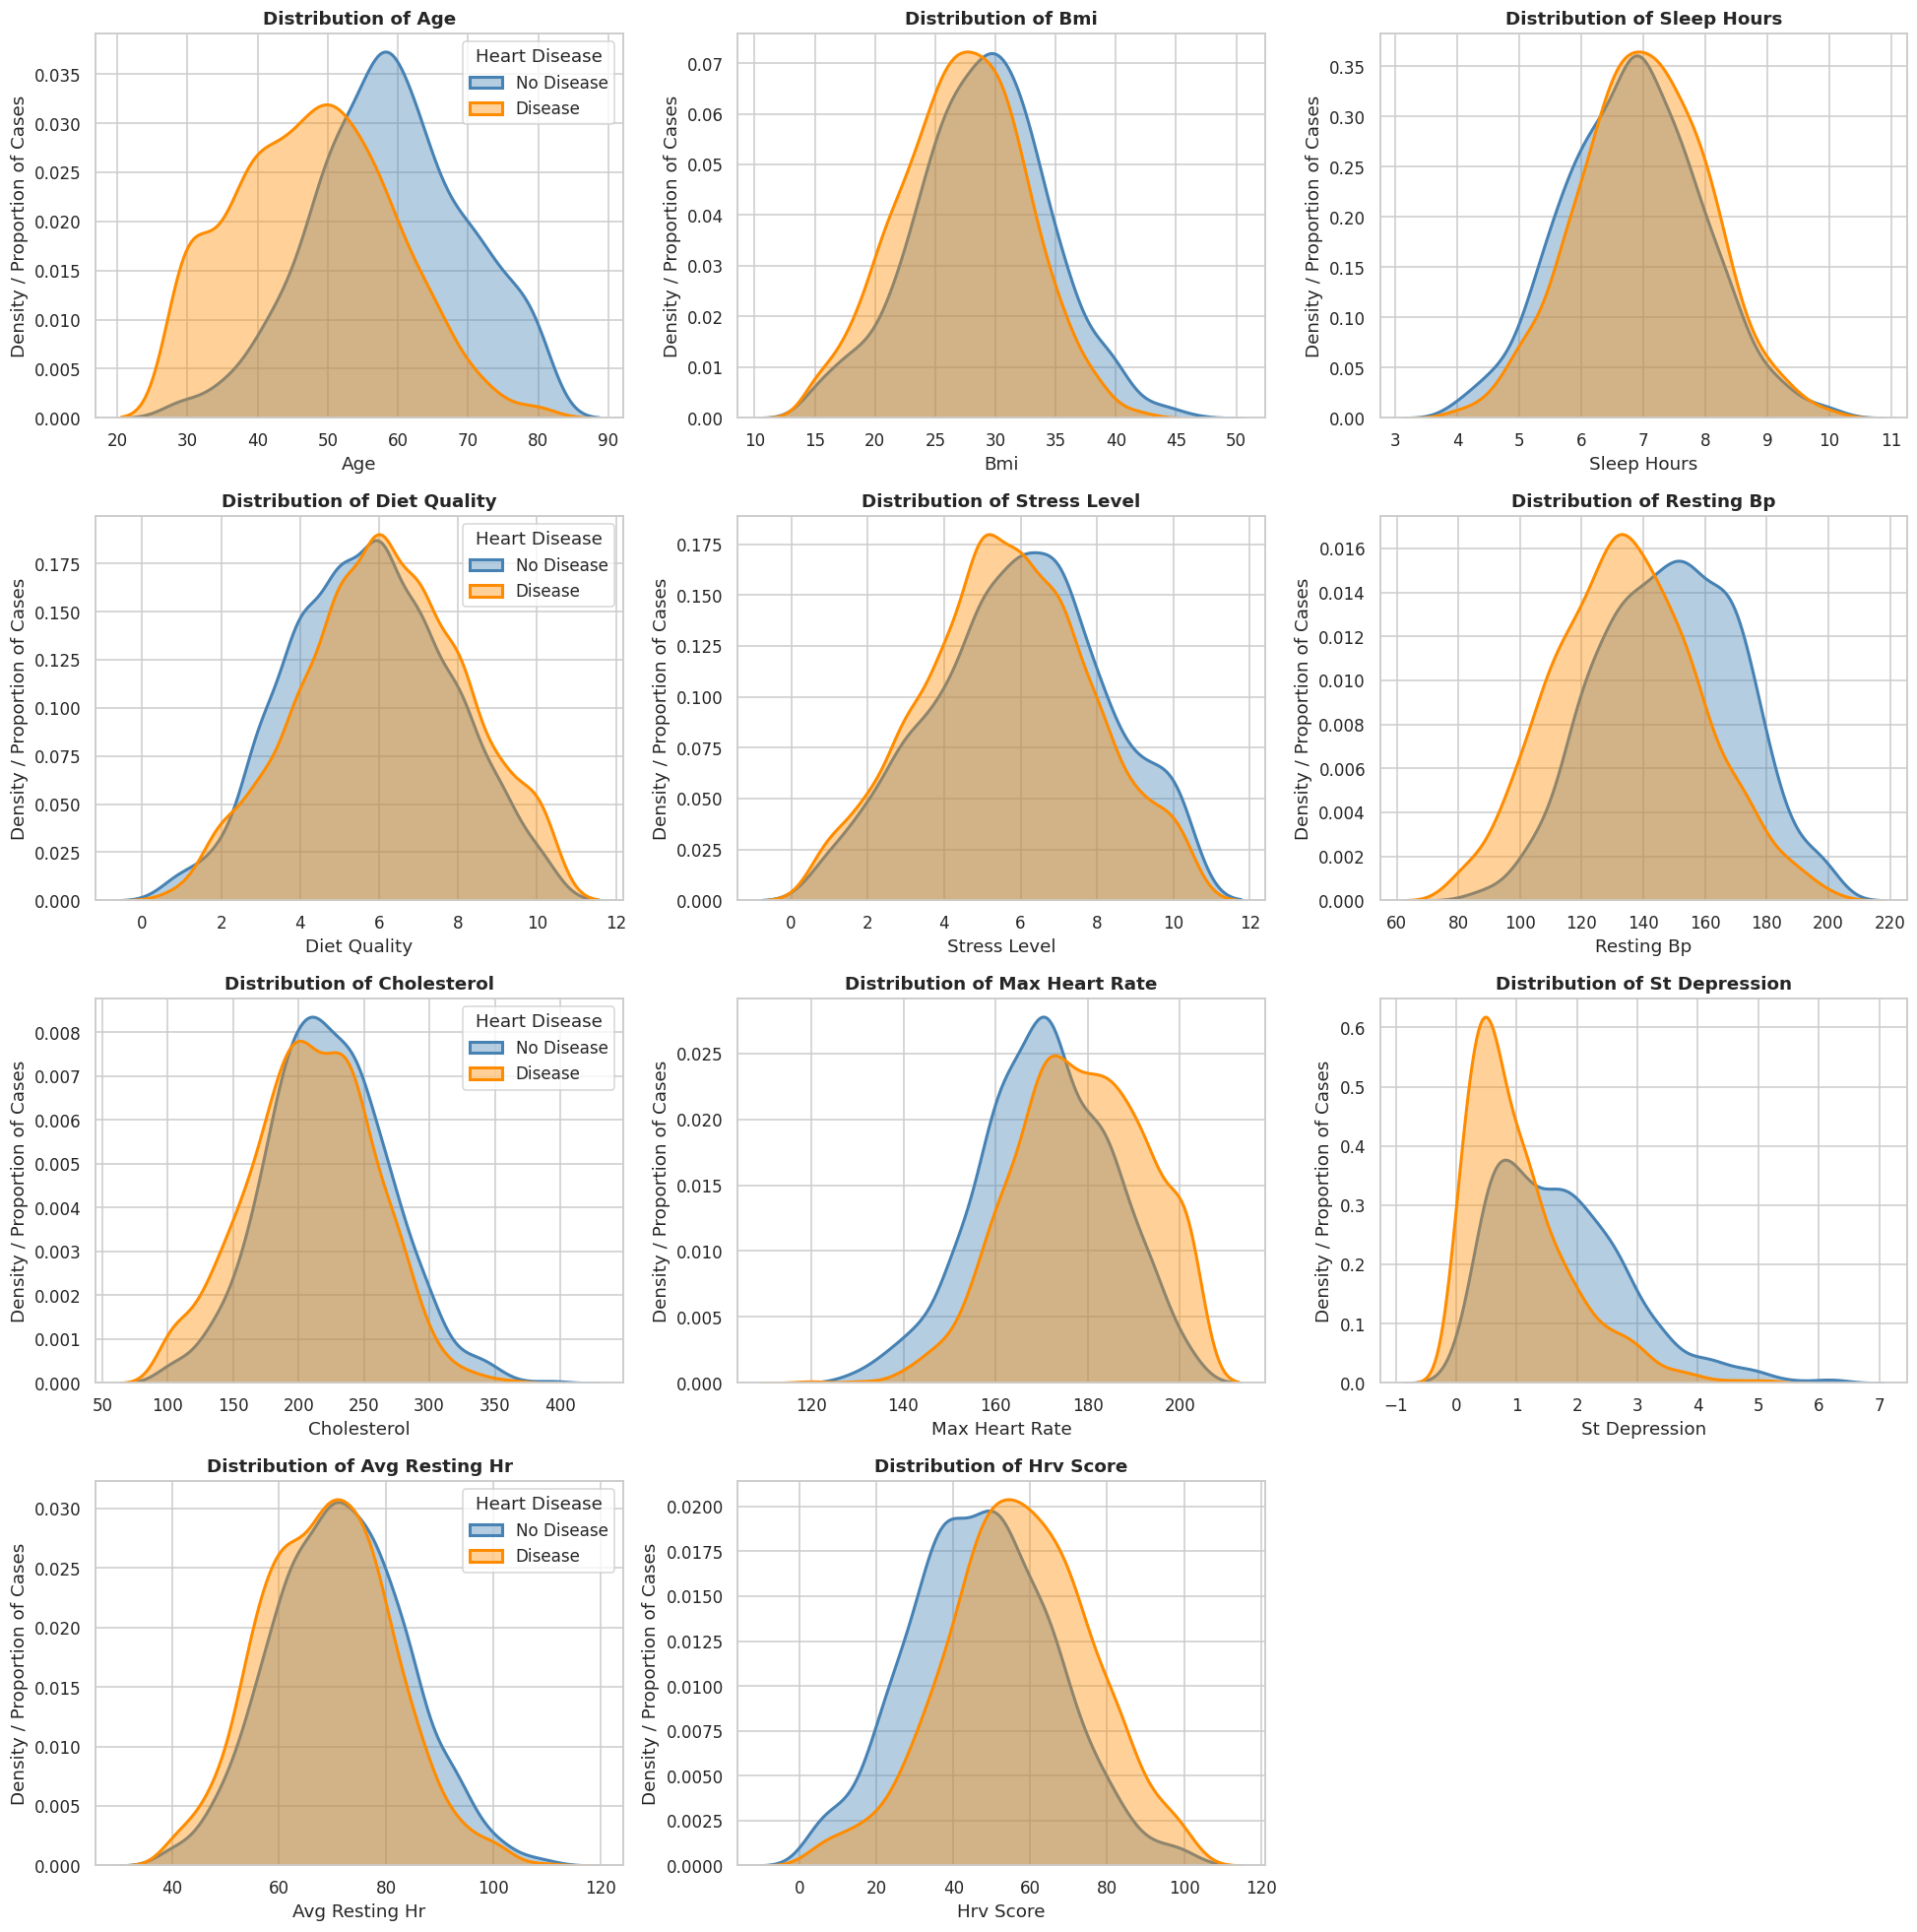

In [71]:
# ---- Initialize the subplot grid ----
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 4.5 * 4))
axes = axes.flatten()

# ---- Loop through each variable and plot the distributions ----
for i, var in enumerate(continuous_vars):
    sns.kdeplot(data=train, x=var, hue="heart_disease", fill=True, common_norm=False, palette={0: "darkorange", 1: "steelblue"}, alpha=0.4, linewidth=2, ax=axes[i])

    axes[i].set_title(f"Distribution of {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Density / Proportion of Cases")

    legend = axes[i].get_legend()
    legend.set_title("Heart Disease")
    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease")
    else:
        axes[i].get_legend().remove()

# ---- Hide the final empty subplot (12th slot) ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

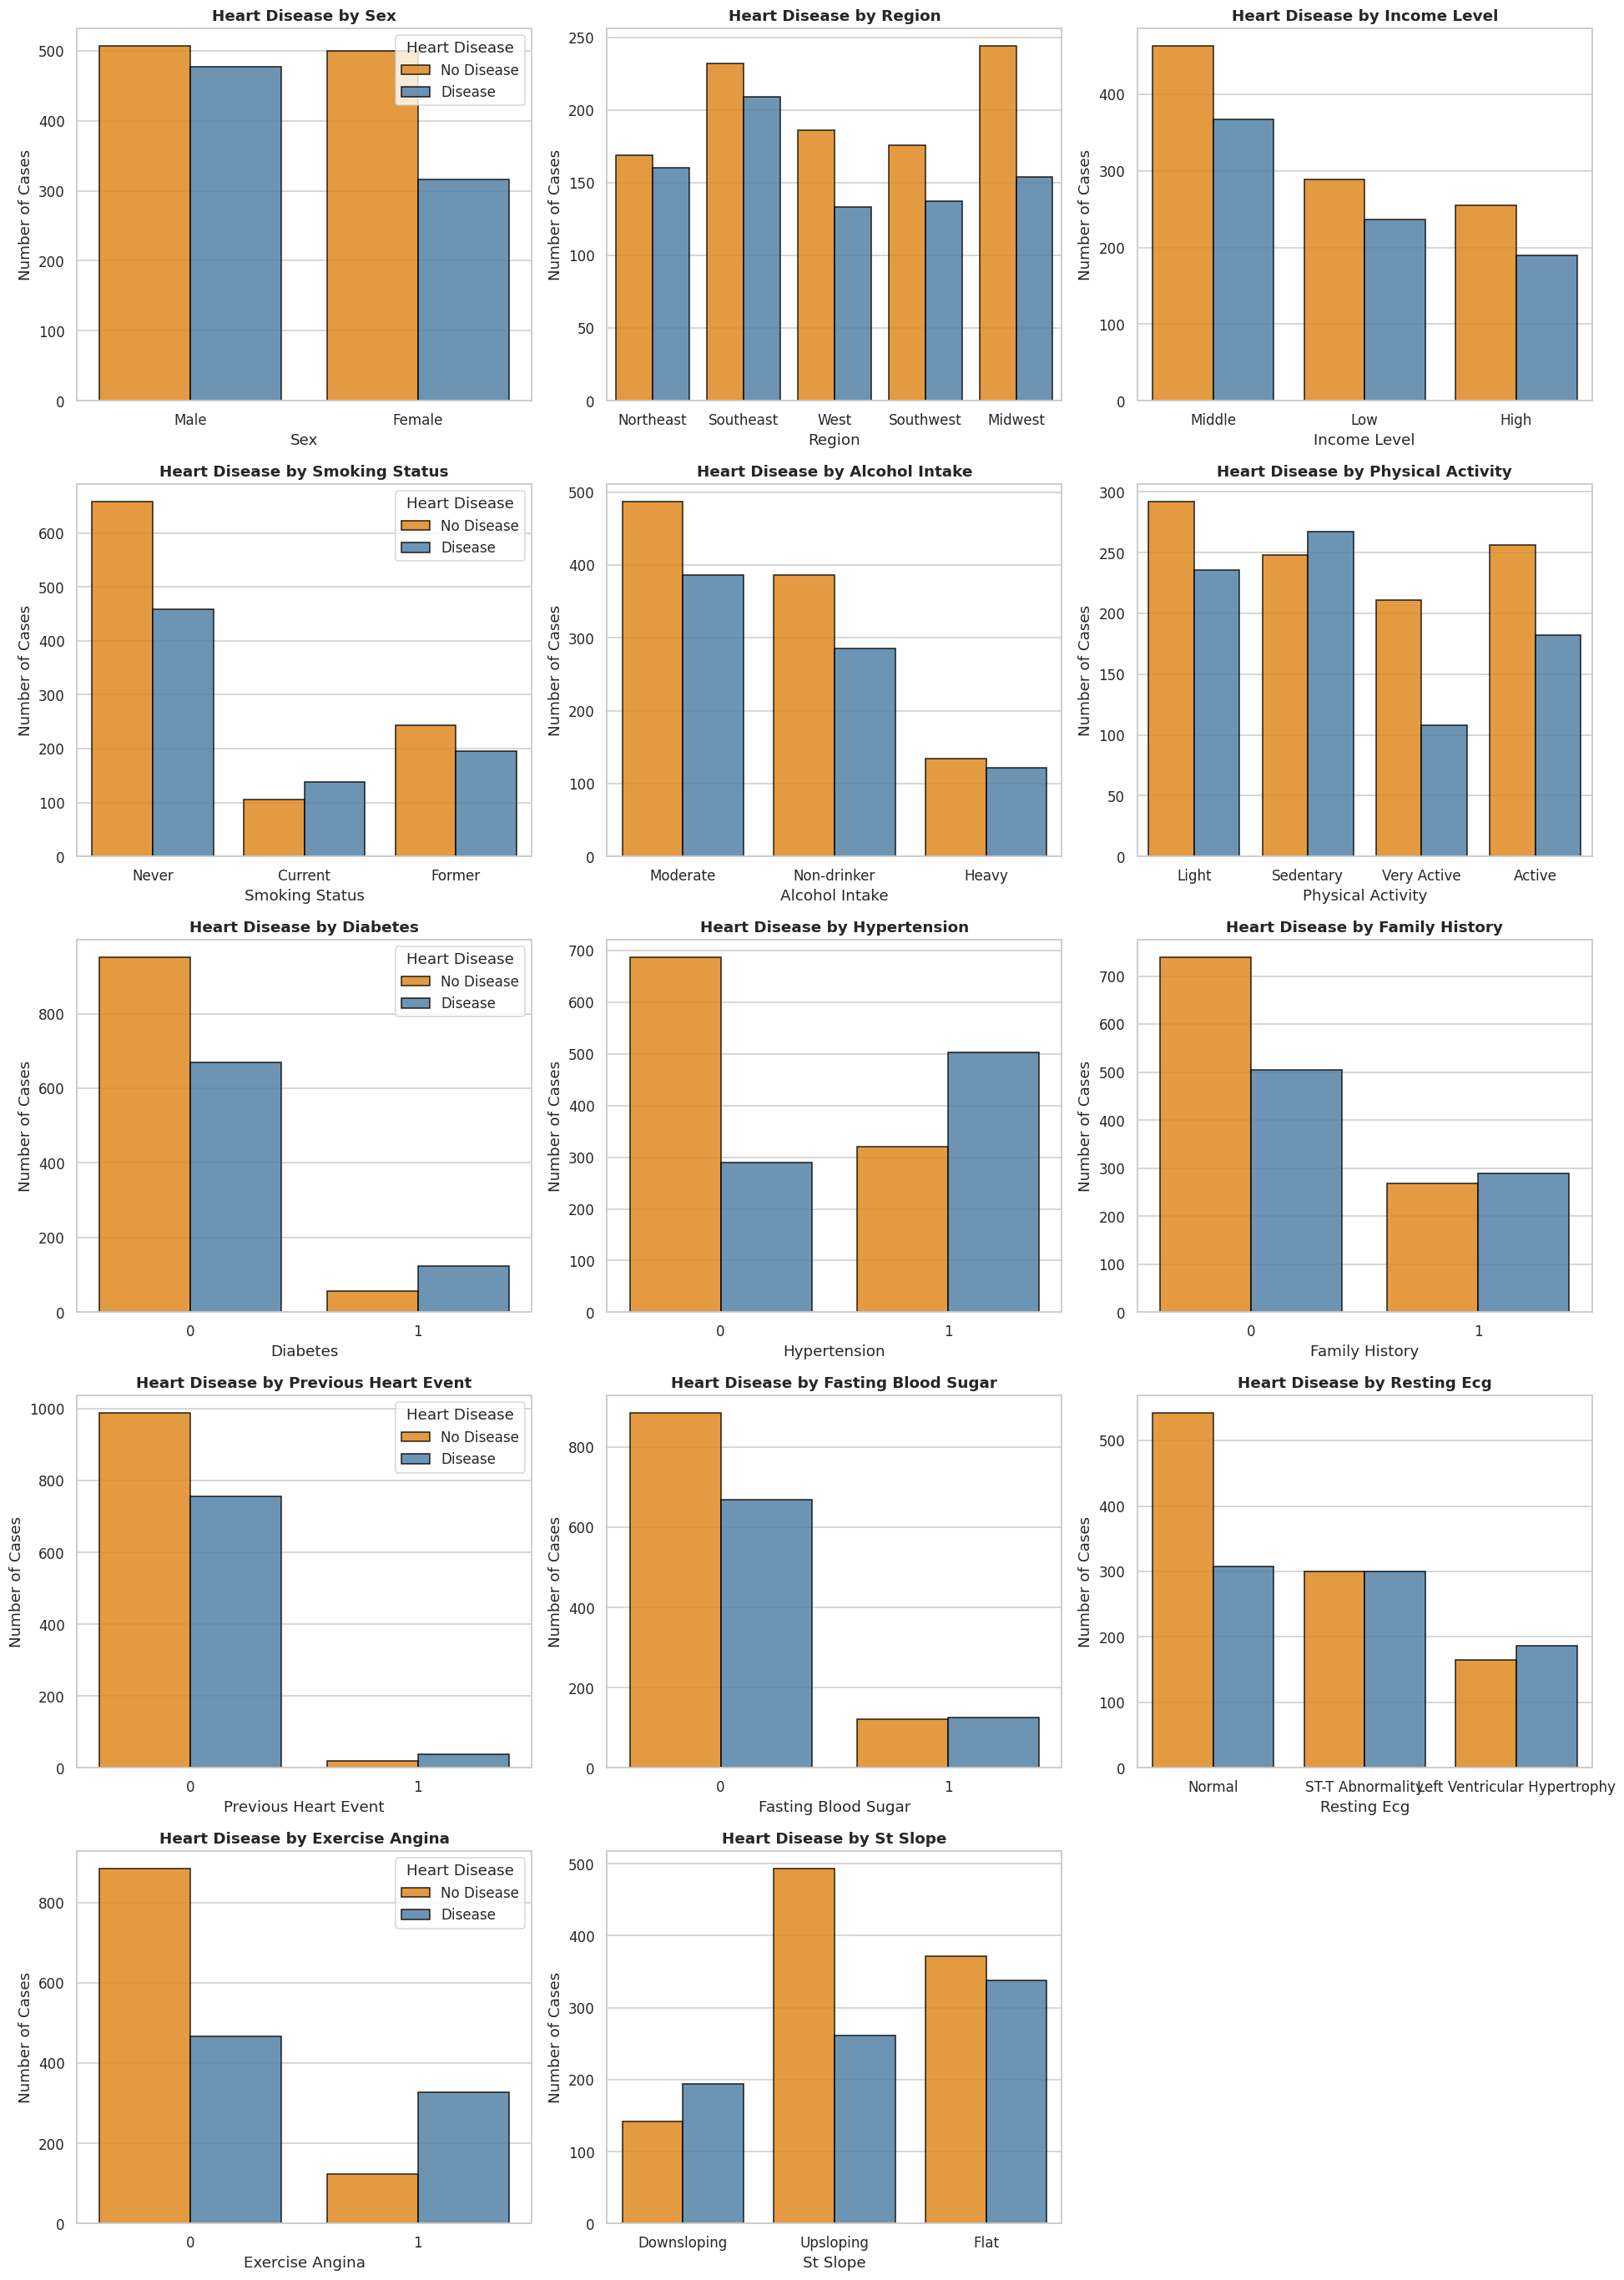

In [72]:
# ---- Initialize the subplot grid ----
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 25))
axes = axes.flatten()

# ---- Loop through each variable and plot the categorical counts
for i, var in enumerate(categorical_vars):
    sns.countplot(data=train, x=var, hue="heart_disease", palette={0: "darkorange", 1: "steelblue"}, alpha=0.85, edgecolor="black", linewidth=1, ax=axes[i])

    axes[i].set_title(f"Heart Disease by {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Number of Cases")

    legend = axes[i].get_legend()
    legend.set_title("Heart Disease")
    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease")
    else:
        axes[i].get_legend().remove()

# ---- Hide the final empty subplot (15th slot) since we only have 14 variables ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

**Analysis of Graphs Generated:**

1. **Time-of-day (`hour`) is by far the dominant driver, and its effect is conditional on `workingday`.**
On working days demand is bimodal with commuter spikes at **08:00** and
**17:00–18:00**, and the least at **03:00–04:00**. On weekends and holidays the same variable produces a completely different,
single-humped leisure profile peaking around **13:00–15:00** with a much shallower night
trough (≈ 9).

2. **Weather effects are real but secondary, and non-linear.** `temp`/`atemp` rise with demand up to
roughly 30–33 °C and then plateau or decline — a quadratic shape, not a straight line. `humidity` is
monotonically negative. `weather` severity is strongly ordered: mean count falls from
**203.8** (clear, 6,945 rows) to **176.5** (mist, 2,686) to **122.4** (light rain/snow, 818), with a
**single** level-4 observation from which nothing can be estimated. `windspeed` is weak and noisy.

3. **There is a strong seasonal cycle and a year-over-year growth trend.** Fall/summer months carry
roughly double the demand of January–February, and 2012 averages **237.1** rentals/hour against
**143.6** in 2011.

4. **`holiday` is almost uninformative on its own** as its boxplot
largely overlaps the non-holiday one; the information it carries is already contained in `workingday`.

5. Finally, `temp` and `atemp` are almost perfectly collinear. Both are retained because
Ridge handles collinearity gracefully, but neither coefficient can be interpreted individually.

## Information Analysis

--- Correlation with Heart Disease ---
age               0.4391
st_depression     0.3386
resting_bp        0.2880
bmi               0.1520
cholesterol       0.1365
avg_resting_hr    0.1077
stress_level      0.0780
sleep_hours      -0.0792
diet_quality     -0.0909
hrv_score        -0.2463
max_heart_rate   -0.2599
Name: heart_disease, dtype: float64
---------------------------------------


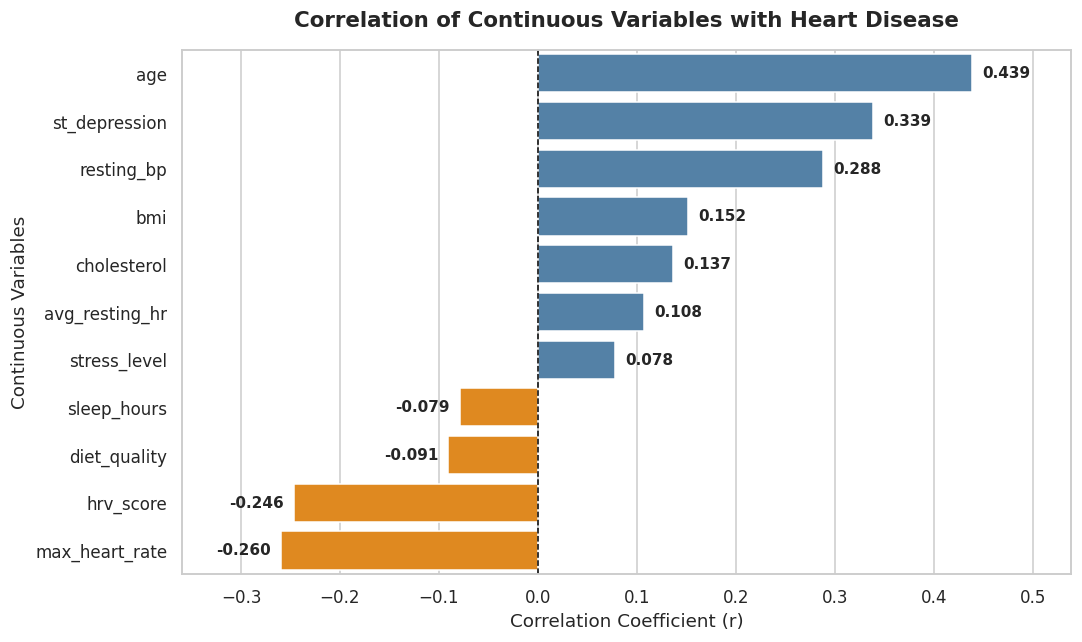

In [73]:
# ---- Add 'heart_disease' to the list to compute the correlation matrix ----
columns_to_analyze = continuous_vars + ["heart_disease"]

# ---- Calculate correlations and isolate the 'heart_disease' column ----
correlation_series = (
    train[columns_to_analyze]
    .corr()["heart_disease"]
    .drop("heart_disease")
    .sort_values(ascending=False)
)

# ---- Print the numeric values in the console  ----
print("--- Correlation with Heart Disease ---")
print(correlation_series.round(4))
print("---------------------------------------")

# ---- Use a diverging color scheme to separate positive and negative trends  ----
plt.figure(figsize=(10, 6))
colors = ['steelblue' if val >= 0 else 'darkorange' for val in correlation_series.values]

sns.barplot(x=correlation_series.values, y=correlation_series.index, palette=colors, hue=correlation_series.index, legend=False)

# ---- Add a vertical line at 0 for visual reference  ----
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

plt.title("Correlation of Continuous Variables with Heart Disease", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Correlation Coefficient (r)")
plt.ylabel("Continuous Variables")

# ---- add text labels on the bars showing the exact value  ----
for index, value in enumerate(correlation_series.values):
    ha_direction = 'left' if value >= 0 else 'right'
    offset = 0.01 if value >= 0 else -0.01
    plt.text(value + offset, index, f"{value:.3f}", va='center', ha=ha_direction, fontweight='bold', fontsize=10)

# ---- Adjust margins so labels don't get cut off  ----
plt.xlim(correlation_series.min() - 0.1, correlation_series.max() + 0.1)
plt.tight_layout()
plt.show()

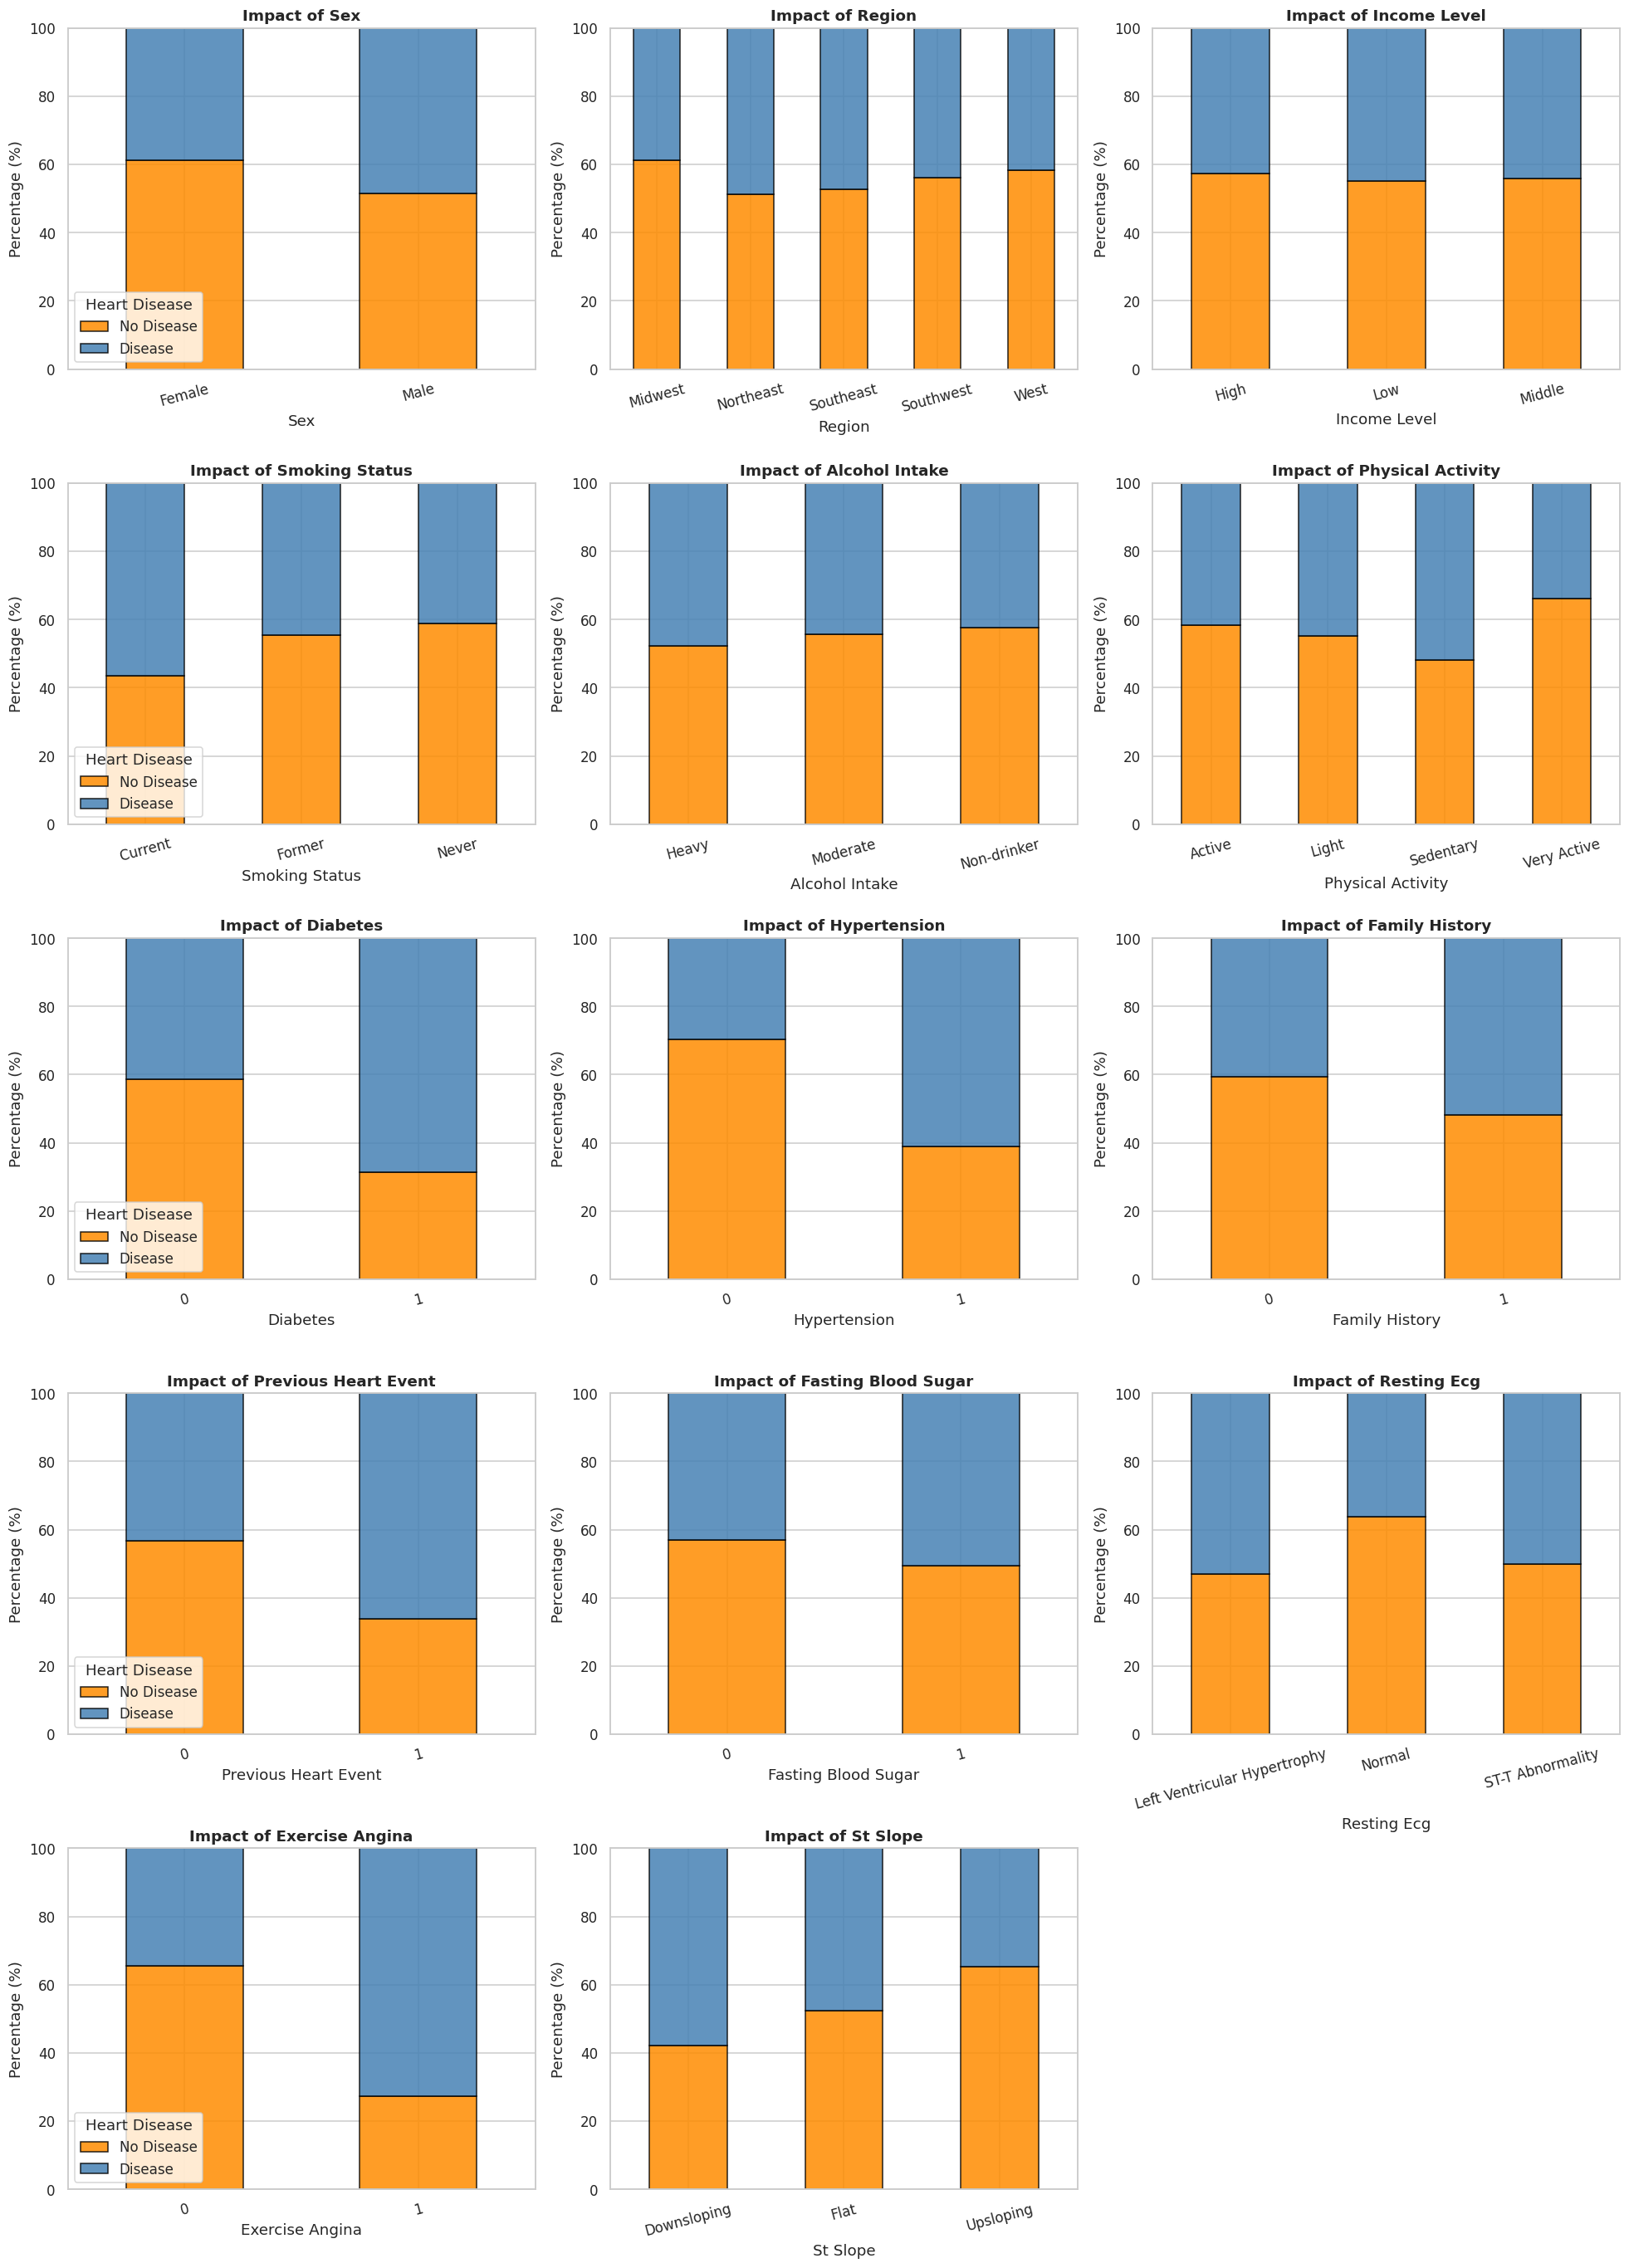

In [74]:
# ---- Setup the subplot grid (5 rows, 3 columns)   ----
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18,25))
axes = axes.flatten()

# ---- Calculate percentages and plot  ----
for i, var in enumerate(categorical_vars):
    # Cross-tabulate and normalize by row to get percentages (0.0 to 1.0)
    crosstab_pct = pd.crosstab(train[var], train['heart_disease'], normalize='index') * 100

    # Plot stacked bars
    crosstab_pct.plot(kind='bar', stacked=True, ax=axes[i], color=["darkorange", "steelblue"], alpha=0.85, edgecolor="black")

    axes[i].set_title(f"Impact of {var.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var.replace('_', ' ').title())
    axes[i].set_ylabel("Percentage (%)")
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis='x', labelrotation=15)

    # Display legends on 1st plot of every row to avoid crowding
    if i % 3 == 0:
        axes[i].legend(["No Disease", "Disease"], title="Heart Disease", loc='lower left')
    else:
        axes[i].get_legend().remove()

# ---- Hide remaining empty subplot slots  ----
axes[-1].axis('off')

plt.tight_layout()
plt.show()

**Analysis of Graphs Generated:**

1. **Time-of-day (`hour`) is by far the dominant driver, and its effect is conditional on `workingday`.**
On working days demand is bimodal with commuter spikes at **08:00** and
**17:00–18:00**, and the least at **03:00–04:00**. On weekends and holidays the same variable produces a completely different,
single-humped leisure profile peaking around **13:00–15:00** with a much shallower night
trough (≈ 9).

2. **Weather effects are real but secondary, and non-linear.** `temp`/`atemp` rise with demand up to
roughly 30–33 °C and then plateau or decline — a quadratic shape, not a straight line. `humidity` is
monotonically negative. `weather` severity is strongly ordered: mean count falls from
**203.8** (clear, 6,945 rows) to **176.5** (mist, 2,686) to **122.4** (light rain/snow, 818), with a
**single** level-4 observation from which nothing can be estimated. `windspeed` is weak and noisy.

3. **There is a strong seasonal cycle and a year-over-year growth trend.** Fall/summer months carry
roughly double the demand of January–February, and 2012 averages **237.1** rentals/hour against
**143.6** in 2011.

4. **`holiday` is almost uninformative on its own** as its boxplot
largely overlaps the non-holiday one; the information it carries is already contained in `workingday`.

5. Finally, `temp` and `atemp` are almost perfectly collinear. Both are retained because
Ridge handles collinearity gracefully, but neither coefficient can be interpreted individually.

## Feature Engineering

In [75]:
# ---- Define updated list of categorical variables  ----
continuous_vars = [
    "age", "bmi", "stress_level",
    "resting_bp", "cholesterol", "st_depression",
    "avg_resting_hr", "hrv_score"
]

categorical_vars = [
    "sex", "smoking_status", "alcohol_intake",
    "physical_activity", "diabetes", "hypertension",
    "family_history", "previous_heart_event"
]

In [76]:
# ---- Drop the unnecesary columns ----
train_new=train.drop(columns=["region","income_level","st_slope","sleep_hours", "diet_quality","max_heart_rate","fasting_blood_sugar","resting_ecg","exercise_angina"])
train_encoded = pd.get_dummies(train_new, columns=categorical_vars, drop_first=True)

# ---- Convert any remaining boolean True/False outputs into clean 1s and 0s ----
dummy_cols = [col for col in train_encoded.columns if col not in df.columns or col in categorical_vars]
train_encoded[dummy_cols] = train_encoded[dummy_cols].astype(int)

# ---- View your newly structured dataset ----
print("--- Encoded DataFrame Preview ---")
print(f"Original shape: {train.shape}")
print(f"Encoded shape: {train_encoded.shape}")
print("\nNew columns added:")
print(list(train_encoded.columns))

--- Encoded DataFrame Preview ---
Original shape: (1800, 26)
Encoded shape: (1800, 28)

New columns added:
['age', 'bmi', 'diet_quality', 'sleep_hours', 'stress_level', 'resting_bp', 'cholesterol', 'max_heart_rate', 'st_depression', 'avg_resting_hr', 'hrv_score', 'heart_disease', 'sex_Male', 'smoking_status_Former', 'smoking_status_Never', 'alcohol_intake_Moderate', 'alcohol_intake_Non-drinker', 'physical_activity_Light', 'physical_activity_Sedentary', 'physical_activity_Very Active', 'diabetes_1', 'hypertension_1', 'family_history_1', 'previous_heart_event_1', 'fasting_blood_sugar_1', 'resting_ecg_Normal', 'resting_ecg_ST-T Abnormality', 'exercise_angina_1']


**Analysis of the Feature Engineering conducted:**

**1. Calendar decomposition of `datetime`.** `datetime` is an identifier and not helpful as a number.
It is decomposed into `year`, `month`, `day`, `hour`, `weekday`, `day_of_ye`, `hour_work`, `hour_weekday`, and `year_month`.

**2. Target transformation.** All models are fitted on **`log1p(count)`** and predictions are mapped
back with `expm1`. This is the most important single modelling decision, for three reasons:
(i) Minimising squared error on `log1p(y)` *is* minimising RMSLE, so training and evaluation are
aligned;

(ii) It converts the multiplicative structure of demand into an additive one, which is what
a linear model can represent; and

(iii) It removes the right-skew and stabilises the error variance. It also guarantees strictly positive predictions after back-transformation.

**3. Dropped columns which could impact the model.** We removed the coloumns `casual` and `registered` as they did not provide accurate combination to the target. `datetime` was removed as we added a normalized replacement `dt`. The target `count` was removed from the input matrix `X`, and added to a separate target variable, `y`.

##Data split

In [86]:
# ---- Separate your features (X) and target variable (y) ----
X = train_encoded.drop(columns=['heart_disease'])
y = train_encoded['heart_disease']

# ---- Re-split your dataset into Train and Test sets ----
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# ---- Initialize the StandardScaler ----
scaler = StandardScaler()

# ---- Fit the scaler on the training data and transform both sets ----
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# ---- Fit & transform the continuous columns on Train; transform only on Test ----
X_train_scaled[continuous_vars] = scaler.fit_transform(X_train[continuous_vars])
X_test_scaled[continuous_vars] = scaler.transform(X_test[continuous_vars])

# ---- Verify the scaled output scales ----
print("--- Scaling Verification ---")
print("Original Age Mean:", X_train['age'].mean().round(2))
print("Scaled Age Mean (Should be ~0):", X_train_scaled['age'].mean().round(2))
print("Scaled Age Standard Deviation (Should be ~1):", np.float64(X_train_scaled['age'].std()).round(2))

--- Scaling Verification ---
Original Age Mean: 52.78
Scaled Age Mean (Should be ~0): -0.0
Scaled Age Standard Deviation (Should be ~1): 1.0


In [87]:
# ---- Splitting the dataset 80:20 into training and validation sets ----
X_train, X_val, y_train, y_val = train_test_split(X,y,test_size=0.20,random_state=42)
print(f"Shape of the Training Sets: Input {X_train.shape}"," | ", f"Target {y_train.shape}")
print(f"Shape of the Validation Sets: Input {X_val.shape}"," | ", f"Target {y_val.shape}")

Shape of the Training Sets: Input (1440, 27)  |  Target (1440,)
Shape of the Validation Sets: Input (360, 27)  |  Target (360,)


## Traning the Models

### Logistic Regression

In [ ]:

# 1. Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)


### Decision Tree

In [ ]:

# 2. Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)


### K-Nearest Neighbours

In [ ]:

# 3. K-Nearest Neighbor Classifier (n_neighbors defaults to 5)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)


### Naive Bayes (Gaussian)

In [ ]:

# 4. Naive Bayes Classifier - Gaussian
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)


### Support Vector Machine

In [ ]:

# 5. Support Vector Machine (SVC)
svm_model = SVC()
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)


# Create a DataFrame to hold all your model outputs
output_df = pd.DataFrame({
    'Actual' : y_test,
    'Logistic_Regression': lr_predictions,
    'Decision_Tree': dt_predictions,
    'KNN': knn_predictions,
    'Naive_Bayes': nb_predictions,
    'SVM': svm_predictions
})



In [65]:
"""#Saving the models

# 1. Create dummy data and train a model
X, y = make_classification(n_samples=100, n_features=4)
model = RandomForestClassifier()
model.fit(X, y)

# 2. Save the trained model to a file
# Pass the model object and your desired file path
joblib.dump(model, 'my_trained_model.joblib')
print("Model saved successfully!")

# 3. Load the model back at a later time
loaded_model = joblib.load('my_trained_model.joblib')

# 4. Use the loaded model to make predictions
predictions = loaded_model.predict(X)"""

'#Saving the models\n\n# 1. Create dummy data and train a model\nX, y = make_classification(n_samples=100, n_features=4)\nmodel = RandomForestClassifier()\nmodel.fit(X, y)\n\n# 2. Save the trained model to a file\n# Pass the model object and your desired file path\njoblib.dump(model, \'my_trained_model.joblib\')\nprint("Model saved successfully!")\n\n# 3. Load the model back at a later time\nloaded_model = joblib.load(\'my_trained_model.joblib\')\n\n# 4. Use the loaded model to make predictions\npredictions = loaded_model.predict(X)'

--- TRAINING AND EVALUATING MODELS ---
Running Logistic Regression...
Running Decision Tree...
Running KNN (K=5)...
Running Naive Bayes (Gaussian)...
Running Support Vector Machine...

========================= MODEL PERFORMANCE REPORT =========================
                        Accuracy  AUC Score  Precision  Recall  F1 Score  \
Logistic Regression       0.7972     0.8825     0.7554  0.7292    0.7420   
Decision Tree             0.6472     0.6435     0.5521  0.6250    0.5863   
KNN (K=5)                 0.7361     0.7887     0.6992  0.5972    0.6442   
Naive Bayes (Gaussian)    0.7917     0.8543     0.7518  0.7153    0.7331   
Support Vector Machine    0.8222     0.8778     0.7941  0.7500    0.7714   

                        MCC Score  
Logistic Regression        0.5753  
Decision Tree              0.2825  
KNN (K=5)                  0.4400  
Naive Bayes (Gaussian)     0.5629  
Support Vector Machine     0.6269  



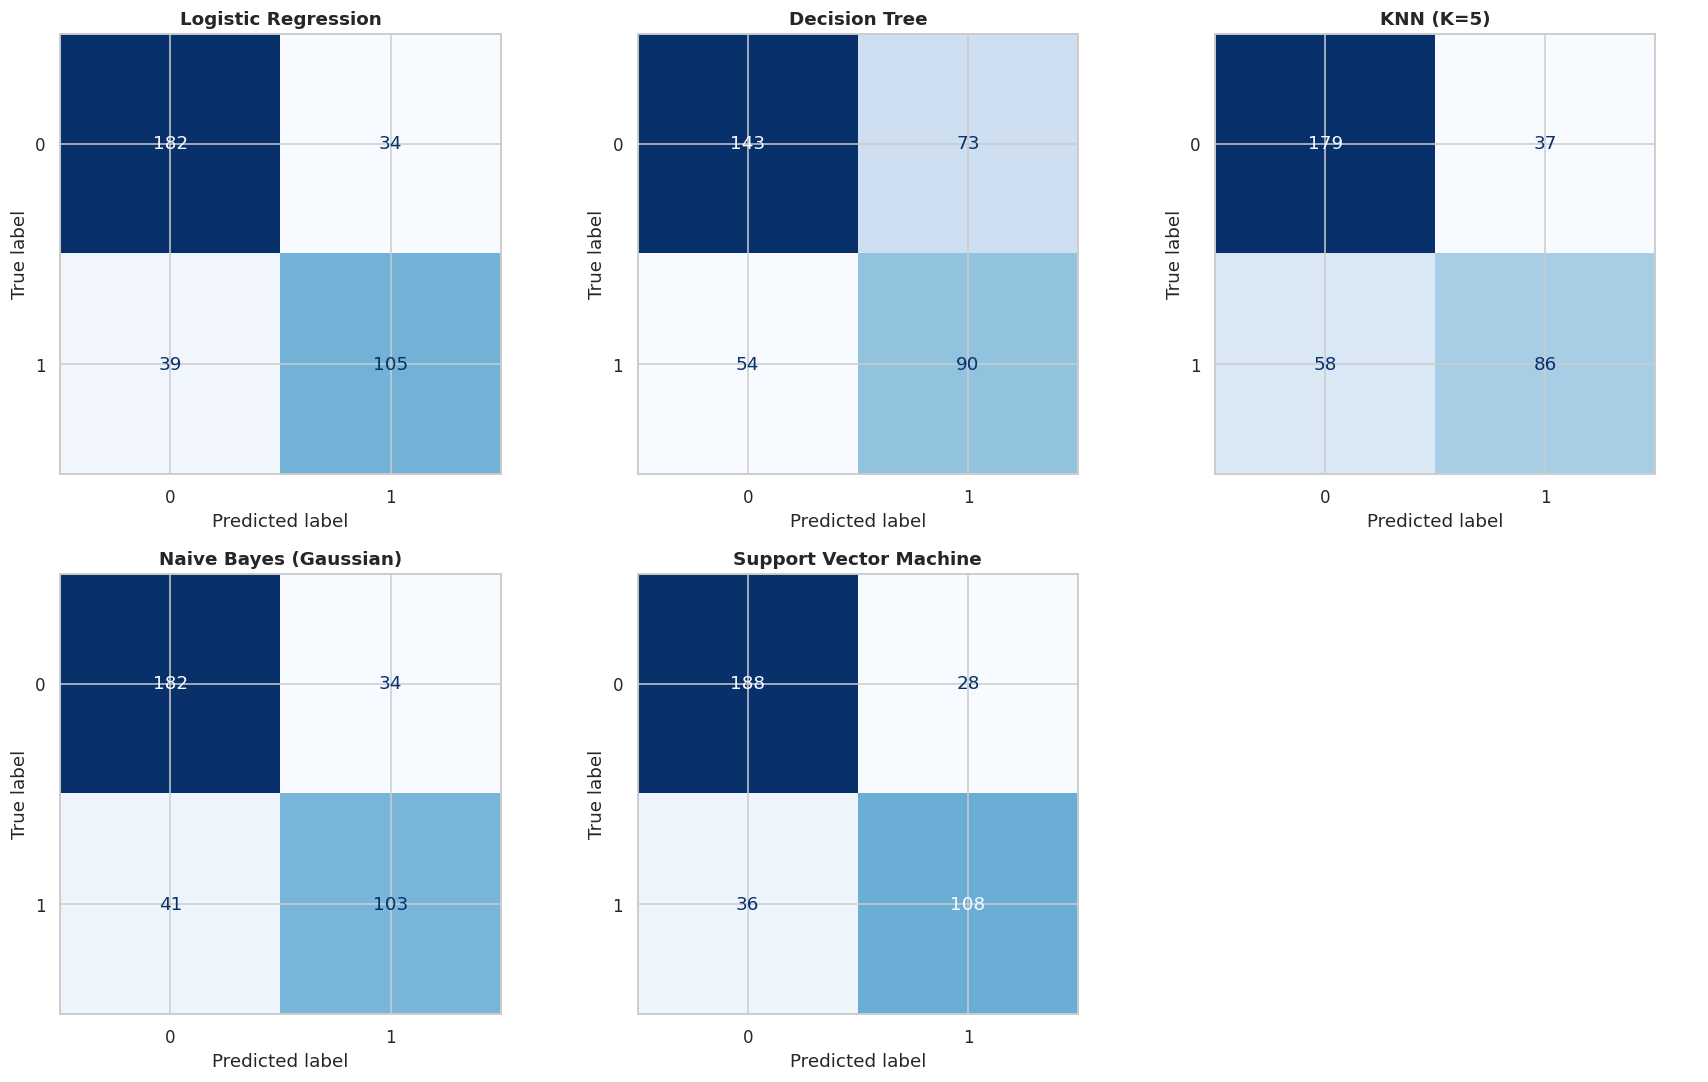

In [88]:
# 1. Initialize all 5 classifiers
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes (Gaussian)': GaussianNB(),
    'Support Vector Machine': SVC(probability=True, random_state=42)
    # (probability=True is required for calculation of exact AUC scores on SVM)
}

# 2. Setup structures to hold evaluation results
performance_results = {}

# Set up a grid layout (2 rows, 3 columns to fit all 5 models cleanly)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()  # Convert grid to a 1D list for easier looping

print("--- TRAINING AND EVALUATING MODELS ---")

# 3. Loop through each model to train, predict, and evaluate
for idx, (model_name, model_instance) in enumerate(models.items()):
    print(f"Running {model_name}...")

    # Train the model on scaled training features
    model_instance.fit(X_train_scaled, y_train)

    # Generate hard class predictions (0 or 1) for metrics and confusion matrices
    y_pred = model_instance.predict(X_test_scaled)

    # Generate predicted probabilities for the positive class (1) to get accurate AUC scores
    y_prob = model_instance.predict_proba(X_test_scaled)[:, 1]

    # Calculate all 6 core metrics requested
    performance_results[model_name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC Score': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'MCC Score': matthews_corrcoef(y_test, y_pred)
    }

    # Generate and plot the visual Confusion Matrix on its assigned grid axis
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[idx],
        cmap='Blues',
        colorbar=False
    )
    axes[idx].set_title(model_name, fontsize=12, fontweight='bold')

# Hide the unused 6th subplot axis slot
axes[5].axis('off')

# 4. Display the comprehensive performance report table
metrics_df = pd.DataFrame(performance_results).T

print("\n========================= MODEL PERFORMANCE REPORT =========================")
print(metrics_df.round(4))
print("============================================================================\n")

# 5. Render the side-by-side charts
plt.tight_layout()
plt.show()

/tmp/ipykernel_2883/1611705879.py:34: UserWarning: The palette list has more values (27) than needed (15), which may not be intended.
  sns.barplot(
/tmp/ipykernel_2883/1611705879.py:48: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.barplot(


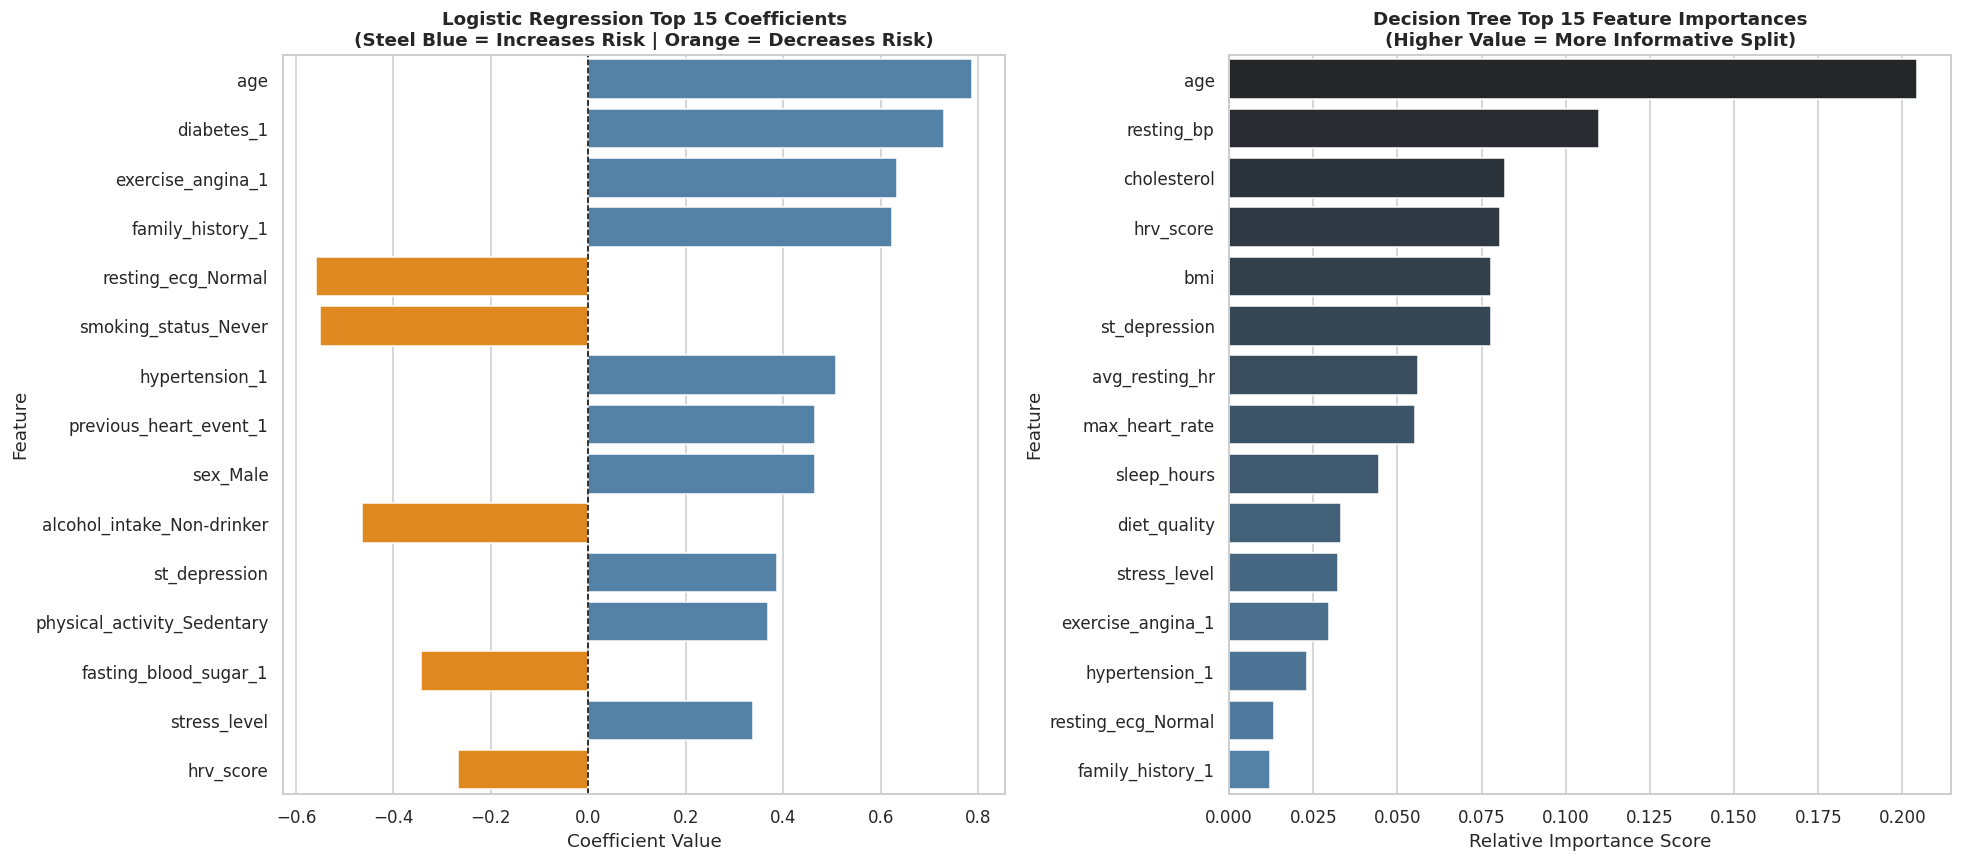

--- TOP 5 MOST INFLUENTIAL FEATURES ---
Logistic Regression: ['age', 'diabetes_1', 'exercise_angina_1', 'family_history_1', 'resting_ecg_Normal']
Decision Tree:       ['age', 'resting_bp', 'cholesterol', 'hrv_score', 'bmi']


In [89]:
# Get the exact feature names after one-hot encoding
feature_names = X_train_scaled.columns

# ==========================================
# 1. EXTRACT LOGISTIC REGRESSION COEFFICIENTS
# ==========================================
# Positive coefficients increase risk; negative coefficients decrease risk
lr_coefs = models['Logistic Regression'].coef_[0]
lr_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_coefs,
    'Absolute_Importance': np.abs(lr_coefs)
}).sort_values(by='Absolute_Importance', ascending=False)

# ==========================================
# 2. EXTRACT DECISION TREE IMPORTANCES
# ==========================================
# All values are between 0 and 1, summing up to 1
dt_importances = models['Decision Tree'].feature_importances_
dt_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_importances
}).sort_values(by='Importance', ascending=False)


# ==========================================
# 3. PLOT BOTH SIDE-BY-SIDE
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

# Plot 1: Logistic Regression
# Color code by direction: blue for positive risk, orange for protective factor
lr_colors = ['steelblue' if x >= 0 else 'darkorange' for x in lr_importance_df['Coefficient']]
sns.barplot(
    data=lr_importance_df.head(15),  # Show top 15 most influential features
    x='Coefficient',
    y='Feature',
    palette=lr_colors,
    hue='Feature',
    legend=False,
    ax=axes[0]
)
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=1)
axes[0].set_title("Logistic Regression Top 15 Coefficients\n(Steel Blue = Increases Risk | Orange = Decreases Risk)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Coefficient Value")

# Plot 2: Decision Tree
sns.barplot(
    data=dt_importance_df.head(15),  # Show top 15 most influential features
    x='Importance',
    y='Feature',
    color='steelblue',
    hue='Feature',
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Decision Tree Top 15 Feature Importances\n(Higher Value = More Informative Split)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.show()

# Print the top 5 features for quick verification in text form
print("--- TOP 5 MOST INFLUENTIAL FEATURES ---")
print(f"Logistic Regression: {list(lr_importance_df['Feature'].head(5))}")
print(f"Decision Tree:       {list(dt_importance_df['Feature'].head(5))}")

In [66]:
"""
# Put your true labels and all model predictions into a dictionary
predictions_dict = {
    'Logistic Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'KNN': knn_predictions,
    'Naive Bayes': nb_predictions,
    'SVM': svm_predictions
}

# Dictionary to store performance results
performance_results = {}

print("--- CONFUSION MATRICES ---")

for model_name, y_pred in predictions_dict.items():
    # 1. Generate and display the Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    print(f"\n{model_name}:")
    print(cm)

    # 2. Calculate all 6 requested metrics
    performance_results[model_name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'AUC Score': roc_auc_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'MCC Score': matthews_corrcoef(y_true, y_pred)
    }

# 3. Convert metrics to a clean comparative table
metrics_df = pd.DataFrame(performance_results).T
print("\n--- MODEL PERFORMANCE METRICS ---")
print(metrics_df.round(4))
"""

"""
# Dictionary matching your models and their predictions
predictions_dict = {
    'Logistic Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'KNN': knn_predictions,
    'Naive Bayes': nb_predictions,
    'SVM': svm_predictions
}

# Set up a grid layout (2 rows, 3 columns to fit all 5 models)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.flatten()  # Flatten the 2D grid into a 1D array for easy looping

for i, (model_name, y_pred) in enumerate(predictions_dict.items()):
    # Plot the matrix on the specific grid axis
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        ax=axes[i],
        cmap='Blues',
        colorbar=False
    )
    axes[i].set_title(model_name, fontsize=14, fontweight='bold')

# Turn off the empty 6th subplot slot since we only have 5 models
axes[5].axis('off')

plt.tight_layout()
plt.show()
"""

"\n# Dictionary matching your models and their predictions\npredictions_dict = {\n    'Logistic Regression': lr_predictions,\n    'Decision Tree': dt_predictions,\n    'KNN': knn_predictions,\n    'Naive Bayes': nb_predictions,\n    'SVM': svm_predictions\n}\n\n# Set up a grid layout (2 rows, 3 columns to fit all 5 models)\nfig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))\naxes = axes.flatten()  # Flatten the 2D grid into a 1D array for easy looping\n\nfor i, (model_name, y_pred) in enumerate(predictions_dict.items()):\n    # Plot the matrix on the specific grid axis\n    disp = ConfusionMatrixDisplay.from_predictions(\n        y_true,\n        y_pred,\n        ax=axes[i],\n        cmap='Blues',\n        colorbar=False\n    )\n    axes[i].set_title(model_name, fontsize=14, fontweight='bold')\n\n# Turn off the empty 6th subplot slot since we only have 5 models\naxes[5].axis('off')\n\nplt.tight_layout()\nplt.show()\n"

In [ ]:
# ---- Define the Coloumns/Features to be used in Training ----
raw_cols = [
    'season',
    'holiday',
    'workingday',
    'weather',
    'temp',
    'atemp',
    'humidity',
    'windspeed']

In [ ]:
# ---- M1: the simplest possible model -- raw features, untransformed target ----
m1 = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())])
register("M1  LinearRegression | raw features, y=count", m1, raw_cols,
         log_target=False)

# ---- M2: identical model, but fitted on log1p(count) ----
register("M2  LinearRegression | raw features, y=log1p", m1, raw_cols,
         log_target=True)

In [ ]:
# ---- Plot the Predictions from the Models M1, and M2 ----
m1_fit, m1_features, _ = FITTED["M1  LinearRegression | raw features, y=count"]
m2_fit, m2_features, _ = FITTED["M2  LinearRegression | raw features, y=log1p"]
pred_val_m1 = np.clip(m1_fit.predict(X_val[m1_features]), 1, None)
pred_val_m2 = np.clip(np.expm1(m2_fit.predict(X_val[m2_features])), 1, None)

fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0,0].scatter(pred_val_m1, y_val, s=6, alpha=.25)
lim = [0, max(y_val.max(), pred_val_m1.max())]
ax[0,0].plot(lim, lim, "r--", lw=1)
ax[0,0].set_xlabel("predicted"); ax[0,0].set_ylabel("actual"); ax[0,0].set_title("M1: predicted vs actual")
tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m1})
h = tmp.groupby("hour")[["actual", "pred"]].mean()
ax[0,1].plot(h.index, h["actual"], "o-", label="actual")
ax[0,1].plot(h.index, h["pred"], "s--", label="M1 predicted")
ax[0,1].set_xlabel("hour of day"); ax[0,1].set_ylabel("mean count"); ax[0,1].legend()
ax[0,1].set_title("M1 is flat; unable to reflect time information")

ax[1,0].scatter(pred_val_m2, y_val, s=6, alpha=.25)
lim = [0, max(y_val.max(), pred_val_m2.max())]
ax[1,0].plot(lim, lim, "r--", lw=1)
ax[1,0].set_xlabel("predicted"); ax[1,0].set_ylabel("actual"); ax[1,0].set_title("M2: predicted vs actual")
tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m2})
h = tmp.groupby("hour")[["actual", "pred"]].mean()
ax[1,1].plot(h.index, h["actual"], "o-", label="actual")
ax[1,1].plot(h.index, h["pred"], "s--", label="M2 predicted")
ax[1,1].set_xlabel("hour of day"); ax[1,1].set_ylabel("mean count"); ax[1,1].legend()
ax[1,1].set_title("M2 is flat; unable to reflect time information")

plt.tight_layout()
plt.show()

**Analysis of the Linear Regression Models:**

**Split.** An 80/20 split produced with `train_test_split` giving the sets with shapes as follows -

Training: Input (8360, 17)  |  Target (8360,)

Validation: Input (2090, 17)  |  Target (2090,)

**Baseline results.**


| Model | Train RMSLE | Validation RMSLE |
|---|---|---|
| M1 — `LinearRegression` & Raw features, target = `count` | 1.4416 | **1.3951** |
| M2 — `LinearRegression` & Raw features, target = `log1p(count)` | 1.2485 | **1.2220** |


**Interpretation.**

* Both models are very poor, and for a structural reason: the raw feature set contains **no time
  information whatsoever**. `datetime` is a string identifier and cannot enter a regression, so the
  model is left with weather and calendar-category variables only. By seeing the Right Plots, both M1 and M2 cannot identify the increase in number of rentals caused by the `hour` of the day.
* **The log transform produces 12 % improvement (1.3951 → 1.2220) with no change to the
  features.** Fitting least squares on `log1p(y)` helps to minimise the RMSLE objective.
* **Inference from Final accuracy**. The model is *under-fitting* as both the `Train RMSLE` & `Validation RMSLE` are bad. This shows the model is rigid to learn the given features properly.


This baseline is the reference point for Q6, where the deficiency is addressed on two fronts —
**engineering the missing time features**, and then **expanding the feature space non-linearly**. All models will use the log transformation for the prediction.

## Q6. Polynomial, Ridge and Lasso Regression

In [ ]:
cat_cols = [
    'season',
    'holiday',
    'workingday',
    'weather',
    'year',
    'month',
    'weekday',
    'hour',
    'hour_work',
    'hour_weekday',
    'year_month'
]

num_cols = [
    'temp',
    'atemp',
    'humidity',
    'windspeed',
    'day',
    'day_of_ye'
]

all_cols = num_cols + cat_cols

In [ ]:
def make_pipeline(estimator, num_features, cat_features, degree=None, interaction_only=False):
    """
    Preprocessing + estimator.

    Numeric block  -> standardise, then (optionally) PolynomialFeatures of the given degree.
    Categorical    -> one-hot, drop='first' to avoid the dummy-variable trap.
    A second StandardScaler after assembly puts every column on a comparable scale, which is what
    makes a single penalty alpha meaningful across the whole design matrix in Ridge/Lasso.
    """
    num_steps = [("scale", StandardScaler())]
    if degree:
        num_steps.append(("poly", PolynomialFeatures(degree, include_bias=False,
                                                     interaction_only=interaction_only)))
    pre = ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), cat_features)])
    return Pipeline([("pre", pre), ("scale2", StandardScaler()), ("est", estimator)])

### Polynomial Regression

In [ ]:
# ---- Model 3: add the hour x workingday interaction ----
pipe_1 = make_pipeline(LinearRegression(), num_cols, cat_cols)
register("M3  LinearRegression | Time fetaures added under Categorical", pipe_1, all_cols)

# ---- Model 4: Polynomial Regression of Degree 2 ----
pipe_2 = make_pipeline(LinearRegression(), num_cols, cat_cols, degree=2)
register("M4  LinearRegression | Polynomial degree 2 (numeric)", pipe_2, all_cols)

# ---- Model 5: Polynomial Regression of Degree 3 ----
pipe_3 = make_pipeline(LinearRegression(), num_cols, cat_cols, degree=3)
register("M5  LinearRegression | Polynomial degree 3 (numeric)", pipe_3, all_cols)

### Ridge Regression

In [ ]:
# ---- Define Alpha for Ridge and calculate best option ----
ridge_alphas = [0.01, 0.1, 1, 10, 100, 500, 2000, 10000]
ridge_curve = []

for a in ridge_alphas:
    pipe = make_pipeline(Ridge(alpha=a, random_state=12), num_cols, cat_cols, degree=3)
    m = clone(pipe).fit(X_train[all_cols], np.log1p(y_train))
    pred_train = rmsle(y_train, np.clip(np.expm1(m.predict(X_train[all_cols])), 1, None))
    pred_val = rmsle(y_val, np.clip(np.expm1(m.predict(X_val[all_cols])), 1, None))
    ridge_curve.append({"alpha": a, "train_RMSLE": pred_train, "val_RMSLE": pred_val})
ridge_curve = pd.DataFrame(ridge_curve)
best_ridge_alpha = float(ridge_curve.loc[ridge_curve.val_RMSLE.idxmin(), "alpha"])

print("Calculated Validation RMSLE's for each Alpha are:")
display(ridge_curve.round(4))
print("\n\nBest Ridge alpha:", best_ridge_alpha)

### Lasso Regression

In [ ]:
# ---- Define Alpha for Lasso and calculate best option ----
lasso_alphas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
lasso_curve = []
for a in lasso_alphas:
    pipe = make_pipeline(Lasso(alpha=a, max_iter=20, random_state=12), num_cols, cat_cols, degree=3)
    m = clone(pipe).fit(X_train[all_cols], np.log1p(y_train))
    pred_train = rmsle(y_train, np.clip(np.expm1(m.predict(X_train[all_cols])), 1, None))
    pred_val = rmsle(y_val, np.clip(np.expm1(m.predict(X_val[all_cols])), 1, None))
    nz = int(np.sum(m.named_steps["est"].coef_ != 0))
    tot = len(m.named_steps["est"].coef_)
    lasso_curve.append({"alpha": a, "train_RMSLE": pred_train, "val_RMSLE": pred_val,
                        "nonzero_coefs": nz, "total_coefs": tot,
                        "pct_zeroed": round(100 * (1 - nz / tot), 1)})
lasso_curve = pd.DataFrame(lasso_curve)
best_lasso_alpha = float(lasso_curve.loc[lasso_curve.val_RMSLE.idxmin(), "alpha"])

print("Calculated Validation RMSLE's for each Alpha are:")
display(lasso_curve.round(5))
print("\n\nBest Lasso alpha:", best_lasso_alpha)

In [ ]:
# ---- Plot the RMSLE vs Alpha values for Ridge and Lasso models ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, curve, name, best in [(ax[0], ridge_curve, "Ridge (L2)", best_ridge_alpha),
                              (ax[1], lasso_curve, "Lasso (L1)", best_lasso_alpha)]:
    a_.plot(curve.alpha, curve.train_RMSLE, "o-", label="train")
    a_.plot(curve.alpha, curve.val_RMSLE, "s-", label="validation")
    a_.axvline(best, ls="--", c="crimson", lw=1, label=f"best alpha = {best:g}")
    a_.set_xscale("log"); a_.set_xlabel("alpha (log scale)"); a_.set_ylabel("RMSLE")
    a_.set_title(f"{name} on degree-3 polynomial features"); a_.legend()
plt.suptitle("Regularisation paths: the classic underfit/overfit U-shape", y=1.03)
plt.show()

In [ ]:
# ---- Model 6: Polynomial Regression of Degree 2 ----
register(f"M6  Ridge  (alpha={best_ridge_alpha:g}) | poly degree 3",
         make_pipeline(Ridge(alpha=best_ridge_alpha, random_state=12), num_cols, cat_cols, degree=3), all_cols)

# ---- Model 7: Polynomial Regression of Degree 2 ----
register(f"M7  Lasso  (alpha={best_lasso_alpha:g}) | poly degree 3",
         make_pipeline(Lasso(alpha=best_lasso_alpha, max_iter=20, random_state=12), num_cols, cat_cols, degree=3), all_cols)

In [ ]:
# ---- Plot the Predictions from the Models M3, M4, M5, M6 and M7 ----

models=['M3  LinearRegression | Time fetaures added under Categorical',
        'M4  LinearRegression | Polynomial degree 2 (numeric)',
        'M5  LinearRegression | Polynomial degree 3 (numeric)',
        'M6  Ridge  (alpha=10) | poly degree 3',
        'M7  Lasso  (alpha=0.001) | poly degree 3']

fig, ax = plt.subplots(5, 2, figsize=(10, 15))

for i in range (0,5):
    m_fit, m_features, _ = FITTED[f"{models[i]}"]
    pred_val_m = np.clip(np.expm1(m_fit.predict(X_val[m_features])), 1, None)

    ax[i,0].scatter(pred_val_m, y_val, s=6, alpha=.25)
    lim = [0, max(y_val.max(), pred_val_m.max())]
    ax[i,0].plot(lim, lim, "r--", lw=1)
    ax[i,0].set_xlabel("predicted"); ax[i,0].set_ylabel("actual"); ax[i,0].set_title(f"M{i+3}: predicted vs actual")
    tmp = pd.DataFrame({"hour": X_val["hour"].values, "actual": y_val, "pred": pred_val_m})
    h = tmp.groupby("hour")[["actual", "pred"]].mean()
    ax[i,1].plot(h.index, h["actual"], "o-", label="actual")
    ax[i,1].plot(h.index, h["pred"], "s--", label=f"M{i+3} predicted")
    ax[i,1].set_xlabel("hour of day"); ax[i,1].set_ylabel("mean count"); ax[i,1].legend()
    ax[i,1].set_title(f"M{i+3} is able to Predict Well")

plt.tight_layout()
plt.show()

**Analysis of the Advanced Regression Models:**

* **Model 3:** We got the best improvement in RMSLE from *1.2222 to 0.4013* just by using the time data in our training. It shows how import the hour and workday are for accurate predictions.

* **Model 4 & 5:**
Expanding the number of numeric features in Degree 2, and then further with Degree 3 resulted in minor improvemenst from the Degree 1 model. The improvements are small and can be said to be nearly negligible.

* **Model 6:** For Ridge, at **α = 10**, we got the best **0.3904**, but it is also just a slight improvement over the accuracy from M5.
* **Model 7:** For Lasso, at **α = e^-5**, we got the best **0.3904**, but it is identical to the accuracy from M6, Ridge model.


## Q7. Model Comparison

In [ ]:
# ---- Create a Table to show the comparison of the 7 Models generated ----
summary = pd.DataFrame(RESULTS)
summary = summary.sort_values("val_RMSLE").reset_index(drop=True)
summary.insert(0, "rank", summary.index + 1)

view = summary[["rank", "model", "target", "n_features_in",
                "train_RMSLE", "val_RMSLE", "val_RMSE", "time_taken"]]

display(view.style.background_gradient(subset=["val_RMSLE"], cmap="RdYlGn_r").format(precision=3))

**Comparison Regression Models:**

* The simple raw-feature linear model is weakest because it cannot represent the strong nonlinear time-of-day pattern. Feature engineering plus log-target modelling substantially improves performance.

* Polynomial Ridge models perform best because polynomial terms capture nonlinear effects and interactions while Ridge regularization limits coefficient instability.

* We have received the best value for RMSLE (0.390) with the Ridge Regression model when the Degree was 3 and alpha=10.

## Q8. Residual Plot

In [ ]:
# ---- Compute the Residual Values for the Best model ----
BEST_Model = "M6  Ridge  (alpha=10) | poly degree 3"
lin_model, lin_feats, lin_log = FITTED[f"{BEST_Model}"]
pred_val = np.clip(np.expm1(lin_model.predict(X_val[lin_feats])), 1, None)

residuals = y_val - pred_val
resid_log = np.log1p(y_val) - np.log1p(pred_val)

print(f"\nbest model: M6  Ridge  (alpha=10) | poly degree 3")
print(f"  validation RMSLE          : {rmsle(y_val, pred_val):.4f}")
print(f"  log-residual mean / sd    : {resid_log.mean():+.4f} / {resid_log.std():.4f}")

In [ ]:
# ---- Plot the Residual Values for the Best model ----
rv = pd.DataFrame({"hour": X_val["hour"].values, "workingday": X_val["workingday"].values,
                   "r": resid_log, "actual": y_val, "pred": pred_val})

fig, ax = plt.subplots(1, 3, figsize=(16, 6))

ax[0].scatter(pred_val, y_val, s=7, alpha=.28)
lim = [0, max(y_val.max(), pred_val.max())]
ax[0].plot(lim, lim, "r--", lw=1.2)
ax[0].set_xlabel("predicted count")
ax[0].set_ylabel("actual count")
ax[0].set_title("Predicted vs actual (original scale)")


prof = rv.groupby(["workingday", "hour"])[["actual", "pred"]].mean().reset_index()
for wd, style in [(1, "-"), (0, "--")]:
    s = prof[prof.workingday == wd]
    ax[1].plot(s.hour, s.actual, style, marker="o", ms=3,
                  label=f"actual (workingday={wd})")
    ax[1].plot(s.hour, s.pred, style, marker="s", ms=3, alpha=.75,
                  label=f"predicted (workingday={wd})")
ax[1].set_xlabel("hour of day")
ax[1].set_ylabel("mean count")
ax[1].legend(fontsize=7)
ax[1].set_title("Both daily profiles are now reproduced")


ax[2].scatter(pred_val,residuals,alpha=0.3)
ax[2].axhline(0,linestyle='--')
ax[2].set_xlabel('Predicted Count')
ax[2].set_ylabel('Residual (Actual - Predicted)')
ax[2].set_title('Residual Plot — Best Model')

plt.show()

plt.suptitle(f"Residual diagnostics — {BEST_Model}", y=1.02, fontsize=12)
plt.show()

**Analysis on the Residual plots**
* Residuals are plotted for the best model: **M6  Ridge  (alpha=10) | poly degree 3 0.3904**.

* **Predicted vs actual** clusters along the 45° line. At the top end there is a mild tendency to
  under-predict the most extreme peak hours.
* **The Daily Profile panel** shows both fitted daily profiles — bimodal on working days, single-humped
  on weekends — tracking the actual curves closely. This is direct visual confirmation that the
  `hour × workingday` design did what it was intended to do.

## Q9. Why does the winning model perform better?

The winning model works due to 3 conditions:

1. Datetime is converted into hour, weekday, month, year and interaction categories, so the model can represent different demand regimes rather than forcing one straight-line relationship.
2. Polynomial terms capture nonlinear effects of temperature, humidity, windspeed and calendar variables.
3. Ridge regularization shrinks unstable coefficients introduced by the expanded feature space. Training on log1p(count) also makes the fitted target scale more consistent with RMSLE. Together these choices reduce both underfitting and overfitting.

## Q10. Why does RMSLE penalize under-predictions more gently than RMSE?

* RMSLE is ordinary squared error computed on the `log1p` scale, so it measures
**ratio** error rather than **absolute** error. Because `log1p` compresses large values, a shortfall
on a high-demand hour — which is exactly where the largest absolute errors occur — is squeezed into a
small penalty. And crucially, the penalty RMSLE can charge for an under-prediction is **bounded**,
whereas RMSE's is unbounded.

* RMSLE applies the logarithm before measuring the error, so it focuses more on relative or multiplicative differences than absolute differences. It therefore reduces the influence of very large target values compared with RMSE.
* RMSLE is also approximately symmetric for multiplicative over- and under-predictions, so the statement that it specifically penalizes under-predictions more gently is only applicable in comparison to RMSE.

## Q11. What are the trade-offs between model simplicity and predictive power?

* A simple linear model is easy to interpret, fast to train, and less likely to overfit, but it can underfit complex relationships.
* Polynomial features and engineered interactions increase predictive power by modelling nonlinear patterns, but they create more features, increase computation, and can overfit.
* Ridge/Lasso provide regularization: Ridge stabilizes correlated coefficients, while Lasso can shrink some coefficients toward zero and perform feature selection.
* The goal is therefore not maximum complexity, but the simplest model that gives strong validation performance.

## Q12. Why can’t Linear Regression alone capture time-of-day effects effectively?

* If hour is represented as a single numeric variable, ordinary linear regression assumes that moving from 1 to 2 to 3 to 4 hours changes demand in one approximately constant direction.
* Bike demand does not behave this way: demand can be low at night, rise sharply during morning/evening commuting hours, and fall again later.
* This is a nonlinear and interaction-dependent pattern. One-hot encoding of hour, polynomial/cyclical features, and interactions with workingday/weekday allow the model to represent these distinct hourly demand patterns.

## Final Model and submission.csv

In [ ]:
# ---- Use the Best model to create Predictions on the Submission Dataset----
X_test = make_features(test).drop(columns=['datetime'])
final_model, final_feats, final_log = FITTED[f"{BEST_Model}"]
test_pred = np.clip(np.expm1(lin_model.predict(X_test)), 1, None)

print(f"predictions : n={len(test_pred)}  min={test_pred.min():.2f}  "
      f"max={test_pred.max():.2f}  mean={test_pred.mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(y_full, bins=60, ax=ax[0], color="steelblue", stat="density", label="train actual")
sns.histplot(test_pred, bins=60, ax=ax[0], color="crimson", stat="density", alpha=.55, label="test predicted")
ax[0].legend(); ax[0].set_title("Predicted test distribution vs training actuals")

tp = pd.DataFrame({"hour": X_test["hour"].values,
                   "workingday": X_test["workingday"].values, "pred": test_pred})
for wd, style in [(1, "-"), (0, "--")]:
    s = tp[tp.workingday == wd].groupby("hour")["pred"].mean()
    ax[1].plot(s.index, s.values, style, marker="o", ms=3, label=f"workingday={wd}")
ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("mean predicted count"); ax[1].legend()
ax[1].set_title("Predicted hourly profiles on the test set")
plt.show()

In [ ]:
# ---- Save the predictions to submission.csv file ----
submission = pd.DataFrame({'datetime': test['datetime'].values,'count_predicted': test_pred})
submission.to_csv('submission.csv',index=False)

## Submission Validation

In [ ]:
# ---- Verify the submission.csv file ----
print(submission.head())

print("\nShape:")
print(submission.shape)

print("\nColumns:")
print(submission.columns.tolist())

print("\nMissing values:")
print(submission.isna().sum())

print("\nNegative predictions:")
print((submission['count_predicted'] < 0).sum())

In [ ]:
assert submission.shape[0] == test.shape[0]

assert submission.columns.tolist() == [
    'datetime',
    'count_predicted'
]

assert submission['count_predicted'].notna().all()

assert (submission['count_predicted'] >= 0).all()

assert submission['datetime'].equals(
    test['datetime']
)

print("Submission validation passed!")